In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
REPO = '/content/sar-flood-unet'
if os.path.exists(REPO):
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/Ronnelpabalan/sar-flood-unet.git {REPO}
sys.path.insert(0, REPO)
!pip install -q rasterio

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from src.dataset import read_split, load_chip
from src.metrics import valid_mask, MetricAccumulator
from src.filters import lee_filter_db, median_filter_db

DATA_DIR = '/content/drive/MyDrive/sen1floods11'
SPLITS = ['train', 'valid', 'test', 'bolivia']
print('filters module loaded')

Mounted at /content/drive
filters module loaded


In [2]:
data = {s: [(cid, *load_chip(DATA_DIR, cid)) for cid in tqdm(read_split(DATA_DIR, s), desc=s)]
        for s in SPLITS}
print({s: len(v) for s, v in data.items()})

train:   0%|          | 0/252 [00:00<?, ?it/s]

valid:   0%|          | 0/89 [00:00<?, ?it/s]

test:   0%|          | 0/90 [00:00<?, ?it/s]

bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

{'train': 252, 'valid': 89, 'test': 90, 'bolivia': 15}


In [3]:
FILTERS = {'raw': None, 'Lee 5x5': lee_filter_db, 'Median 5x5': median_filter_db}
BANDS = {'VV': 0, 'VH': 1}

bands = {}    # (filter, band) -> {split: [2-D dB array per chip]}
for fname, f in FILTERS.items():
    for bname, b in BANDS.items():
        bands[(fname, bname)] = {
            s: [s1[b] if f is None else f(s1[b]) for cid, s1, lab in data[s]]
            for s in SPLITS}
        print('done:', fname, bname)

done: raw VV
done: raw VH
done: Lee 5x5 VV
done: Lee 5x5 VH
done: Median 5x5 VV
done: Median 5x5 VH


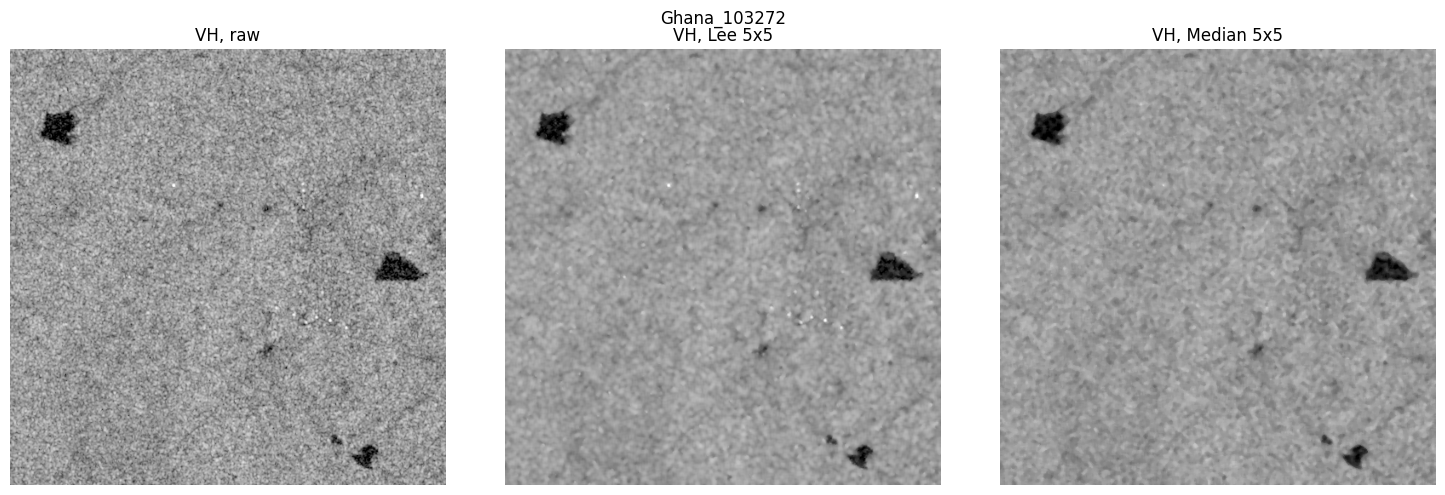

In [4]:
cid, s1, lab = data['train'][0]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, fname in zip(ax, FILTERS):
    a.imshow(bands[(fname, 'VH')]['train'][0], cmap='gray', vmin=-30, vmax=-5)
    a.set_title(f'VH, {fname}'); a.axis('off')
plt.suptitle(cid); plt.tight_layout(); plt.show()

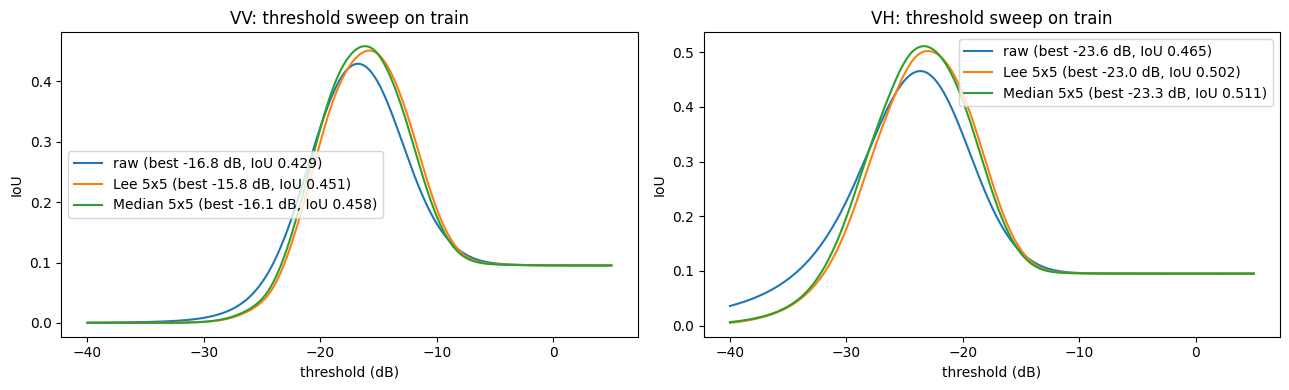

{('raw', 'VV'): -16.8,
 ('raw', 'VH'): -23.6,
 ('Lee 5x5', 'VV'): -15.8,
 ('Lee 5x5', 'VH'): -23.0,
 ('Median 5x5', 'VV'): -16.1,
 ('Median 5x5', 'VH'): -23.3}

In [5]:
EDGES = np.round(np.arange(-40, 5.001, 0.1), 1)
BINS = np.concatenate([[-np.inf], EDGES, [np.inf]])

def sweep(arrays, split):
    """Pooled IoU of 'water if value < t' for every t in EDGES."""
    w_hist = np.zeros(len(BINS) - 1); l_hist = np.zeros(len(BINS) - 1)
    for arr, (cid, s1, lab) in zip(arrays, data[split]):
        v = valid_mask(lab, s1)                 # same pixels as all other methods
        x, y = arr[v], lab[v]
        w_hist += np.histogram(x[y == 1], BINS)[0]
        l_hist += np.histogram(x[y == 0], BINS)[0]
    tp = np.cumsum(w_hist)[:len(EDGES)]
    fp = np.cumsum(l_hist)[:len(EDGES)]
    fn = w_hist.sum() - tp
    return EDGES, tp / (tp + fp + fn)

best_t = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (fname, bname) in enumerate(bands):
    t, iou = sweep(bands[(fname, bname)]['train'], 'train')
    best_t[(fname, bname)] = float(t[np.argmax(iou)])
    ax[BANDS[bname]].plot(t, iou, label=f'{fname} (best {t[np.argmax(iou)]:.1f} dB, IoU {iou.max():.3f})')
for a, bname in zip(ax, BANDS):
    a.set_title(f'{bname}: threshold sweep on train'); a.set_xlabel('threshold (dB)')
    a.set_ylabel('IoU'); a.legend()
plt.tight_layout(); plt.show()
best_t

In [6]:
rows = []
for (fname, bname), arrays in bands.items():
    t = best_t[(fname, bname)]
    for s in SPLITS:
        acc = MetricAccumulator()
        for arr, (cid, s1, lab) in zip(arrays[s], data[s]):
            acc.add(arr < t, lab, valid_mask(lab, s1))
        rows.append({'method': f'{fname} {bname} < {t} dB', 'split': s, **acc.compute()})
extra = pd.DataFrame(rows).round(3)

unet = pd.read_csv(f'{REPO}/results/unet_metrics.csv')
table = pd.concat([extra, unet], ignore_index=True)
for s in ['test', 'bolivia']:
    print(f'\n=== {s.upper()} ===')
    display(table[table['split'] == s].set_index('method')[['iou', 'f1', 'precision', 'recall']]
            .sort_values('iou'))


=== TEST ===


,iou,f1,precision,recall
method,,,,
raw VV < -16.8 dB,0.464,0.634,0.774,0.536
Lee 5x5 VV < -15.8 dB,0.486,0.654,0.804,0.552
Median 5x5 VV < -16.1 dB,0.493,0.661,0.805,0.560
raw VH < -23.6 dB,0.533,0.695,0.747,0.650
Lee 5x5 VH < -23.0 dB,0.585,0.738,0.809,0.678
Median 5x5 VH < -23.3 dB,0.592,0.744,0.812,0.687
U-Net (ResNet34),0.675,0.806,0.819,0.793



=== BOLIVIA ===


,iou,f1,precision,recall
method,,,,
raw VV < -16.8 dB,0.436,0.608,0.881,0.464
Median 5x5 VV < -16.1 dB,0.515,0.680,0.911,0.542
Lee 5x5 VV < -15.8 dB,0.516,0.680,0.907,0.544
raw VH < -23.6 dB,0.535,0.697,0.870,0.581
U-Net (ResNet34),0.576,0.731,0.799,0.674
Lee 5x5 VH < -23.0 dB,0.612,0.759,0.909,0.652
Median 5x5 VH < -23.3 dB,0.617,0.763,0.914,0.655


In [7]:
test_rows = extra[extra['split'] == 'test']
best_name = test_rows[~test_rows['method'].str.startswith('raw')] \
    .sort_values('iou').iloc[-1]['method']        # best filtered variant BY TEST IoU: for this table only
key = next(k for k in bands if best_name.startswith(f'{k[0]} {k[1]}'))
t = best_t[key]

acc = {}
for arr, (cid, s1, lab) in zip(bands[key]['test'], data['test']):
    acc.setdefault(cid.split('_')[0], MetricAccumulator()).add(arr < t, lab, valid_mask(lab, s1))
ev = pd.read_csv(f'{REPO}/results/test_iou_per_event.csv', index_col='event')[['Fixed VH', 'U-Net', 'chips']]
ev.insert(1, best_name, pd.Series({e: a.compute()['iou'] for e, a in acc.items()}))
print('Filtered variant shown:', best_name)
ev.round(3).sort_values('U-Net')

Filtered variant shown: Median 5x5 VH < -23.3 dB


,Fixed VH,Median 5x5 VH < -23.3 dB,U-Net,chips
event,,,,
Pakistan,0.150,0.151,0.311,6
Somalia,0.256,0.278,0.471,6
Ghana,0.453,0.474,0.582,11
USA,0.379,0.500,0.582,14
Paraguay,0.466,0.490,0.659,14
India,0.593,0.650,0.669,14
Spain,0.640,0.674,0.732,6
Sri-Lanka,0.717,0.858,0.801,9
Mekong,0.724,0.741,0.830,6


In [8]:
extra.to_csv('/content/extra_baseline_metrics.csv', index=False)
ev.round(3).to_csv('/content/test_iou_per_event_with_filtered.csv')
from google.colab import files
files.download('/content/extra_baseline_metrics.csv')
files.download('/content/test_iou_per_event_with_filtered.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>